# Lab 8: Newton's Method and Softmax Regression



---
## Task 1: Gradient Descent versus Newton's Method

In this task, we implement and compare two fundamental optimization algorithms for binary Logistic Regression from scratch:
1. **First-order Optimization:** Batch Gradient Descent
2. **Second-order Optimization:** Newton's Method (Newton-Raphson)

### Problem Setup
- **Dataset:** Breast Cancer Wisconsin dataset (`sklearn.datasets.load_breast_cancer`)
- **Features:** All 30 diagnostic features for binary classification.
- **Split:** Stratified 70%–30% train–test split with fixed random seed ($SEED = 42$).
- **Standardization:** Standardize features using training-set statistics only ($\mu_{\text{train}}, \sigma_{\text{train}}$).
- **Model:** Logistic Regression with hypothesis:
  $$h_\theta(x) = \sigma(\theta^T x) = \frac{1}{1 + \exp(-\theta^T x)}$$
- **Loss Function (Binary Cross-Entropy):**
  $$J(\theta) = -\frac{1}{n} \sum_{i=1}^n \left[ y^{(i)} \log(p_i) + (1 - y^{(i)}) \log(1 - p_i) \right]$$


In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from scipy.special import expit

# Set plot style and dpi
plt.rcParams['figure.dpi'] = 100


In [2]:
# Set fixed random seed for reproducibility
SEED = 42
np.random.seed(SEED)

# 1. Load Breast Cancer Wisconsin dataset
data = load_breast_cancer()
X, y = data.data, data.target

# 2. Stratified 70%-30% train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)

# 3. Standardize features using training-set statistics ONLY
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Add bias term (column of 1s at index 0)
X_train_b = np.c_[np.ones((X_train_scaled.shape[0], 1)), X_train_scaled]
X_test_b = np.c_[np.ones((X_test_scaled.shape[0], 1)), X_test_scaled]

# Initialize shared weights (zeros) for fair comparison between GD and Newton's Method
n_features = X_train_b.shape[1]
initial_theta = np.zeros(n_features)

print(f"Dataset: Breast Cancer Wisconsin")
print(f"Total samples: {X.shape[0]}, Features (original): {X.shape[1]}")
print(f"Training shape (with bias): {X_train_b.shape}")
print(f"Testing shape (with bias):  {X_test_b.shape}")
print(f"Class distribution - Train: {np.bincount(y_train)}, Test: {np.bincount(y_test)}")


Dataset: Breast Cancer Wisconsin
Total samples: 569, Features (original): 30
Training shape (with bias): (398, 31)
Testing shape (with bias):  (171, 31)
Class distribution - Train: [148 250], Test: [ 64 107]


In [3]:
def sigmoid(z):
    # Clip z to prevent overflow in exp(-z)
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

def compute_loss(y, p):
    # Clip probabilities to avoid log(0)
    eps = 1e-15
    p = np.clip(p, eps, 1.0 - eps)
    return -np.mean(y * np.log(p) + (1.0 - y) * np.log(1.0 - p))

def predict(X, theta, threshold=0.5):
    probs = sigmoid(X @ theta)
    return (probs >= threshold).astype(int)


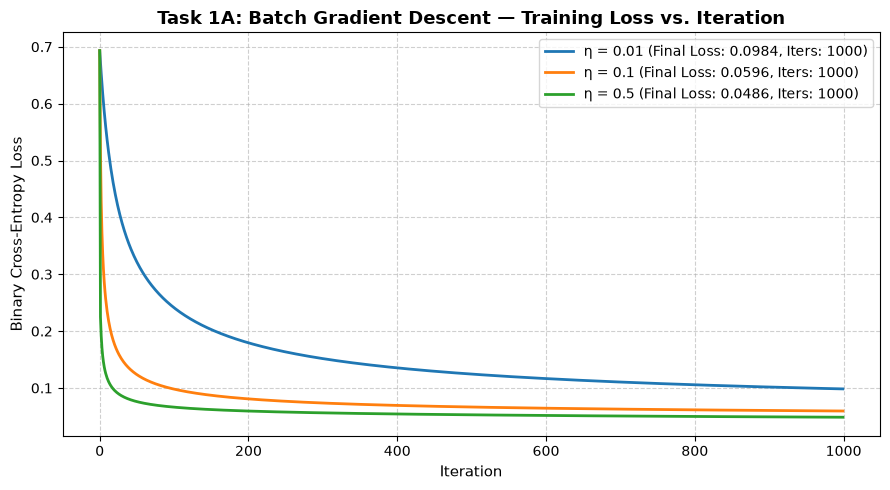

=== Gradient Descent Learning Rate Comparison ===


,Learning Rate (η),Iterations,Final Training Loss,Test Accuracy,Total Time (s),Avg Time/Iter (s)
0,0.01,1000,0.098400,96.49%,0.1691,1.690906e-04
1,0.10,1000,0.059553,97.66%,0.0902,9.021490e-05
2,0.50,1000,0.048604,97.66%,0.1407,1.406765e-04


In [4]:
def train_gradient_descent(X, y, theta_init, lr=0.1, max_iter=1000, tol=1e-6):
    theta = theta_init.copy()
    n = X.shape[0]
    loss_history = []
    
    start_time = time.perf_counter()
    
    for i in range(max_iter):
        # Forward pass: predicted probabilities
        p = sigmoid(X @ theta)
        loss = compute_loss(y, p)
        loss_history.append(loss)
        
        # Compute gradient: g = (1/n) * X^T * (p - y)
        g = (1.0 / n) * (X.T @ (p - y))
        
        # Update parameters: theta <- theta - lr * g
        theta_new = theta - lr * g
        
        # Check convergence (L2 norm of parameter change)
        if np.linalg.norm(theta_new - theta) < tol:
            theta = theta_new
            loss_history.append(compute_loss(y, sigmoid(X @ theta)))
            break
            
        theta = theta_new
        
    total_time = time.perf_counter() - start_time
    num_iters = len(loss_history) - 1 if len(loss_history) > max_iter else i + 1
    avg_time_per_iter = total_time / num_iters
    
    return theta, loss_history, num_iters, total_time, avg_time_per_iter

# Compare learning rates: eta in {0.01, 0.1, 0.5}
learning_rates = [0.01, 0.1, 0.5]
gd_results = {}

plt.figure(figsize=(9, 5))

for lr in learning_rates:
    theta_gd, losses, iters, t_tot, t_avg = train_gradient_descent(
        X_train_b, y_train, initial_theta, lr=lr, max_iter=1000, tol=1e-6
    )
    test_acc = accuracy_score(y_test, predict(X_test_b, theta_gd))
    gd_results[lr] = {
        "theta": theta_gd,
        "losses": losses,
        "iters": iters,
        "final_loss": losses[-1],
        "test_acc": test_acc,
        "total_time": t_tot,
        "avg_time": t_avg
    }
    plt.plot(losses, label=f"η = {lr} (Final Loss: {losses[-1]:.4f}, Iters: {iters})", linewidth=2)

plt.title("Task 1A: Batch Gradient Descent — Training Loss vs. Iteration", fontsize=13, fontweight='bold')
plt.xlabel("Iteration", fontsize=11)
plt.ylabel("Binary Cross-Entropy Loss", fontsize=11)
plt.legend(frameon=True, fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Print summary table for Gradient Descent across learning rates
gd_summary = pd.DataFrame([
    {
        "Learning Rate (η)": lr,
        "Iterations": gd_results[lr]["iters"],
        "Final Training Loss": f"{gd_results[lr]['final_loss']:.6f}",
        "Test Accuracy": f"{gd_results[lr]['test_acc'] * 100:.2f}%",
        "Total Time (s)": f"{gd_results[lr]['total_time']:.4f}",
        "Avg Time/Iter (s)": f"{gd_results[lr]['avg_time']:.6e}"
    }
    for lr in learning_rates
])
print("=== Gradient Descent Learning Rate Comparison ===")
display(gd_summary)


In [5]:
def train_newtons_method(X, y, theta_init, max_iter=50, tol=1e-6):
    theta = theta_init.astype(float).copy()
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)

    n, d = X.shape
    loss_history = []
    damping = 1e-4

    # Stable logistic regression loss
    def calculate_loss(params):
        z = X @ params
        if not np.all(np.isfinite(z)):
            return np.inf
        return np.mean(np.logaddexp(0.0, z) - y * z)

    start_time = time.perf_counter()
    converged = False

    for i in range(max_iter):
        z = X @ theta
        p = expit(z)

        loss = calculate_loss(theta)
        loss_history.append(loss)

        # Gradient: g = (1/n) * X^T * (p - y)
        g = (X.T @ (p - y)) / n

        # Check convergence using gradient infinity-norm
        if np.linalg.norm(g, ord=np.inf) < tol:
            converged = True
            break

        # Hessian: H = (1/n) * X^T * S * X where S = diag(p * (1 - p))
        s_diag = p * (1.0 - p)
        H = (X.T @ (X * s_diag[:, None])) / n

        # Symmetrize Hessian to eliminate tiny numerical asymmetries
        H = 0.5 * (H + H.T)

        # Solve H * Delta = g for Newton step Delta = H^-1 * g
        try:
            delta = np.linalg.solve(H + damping * np.eye(d), g)
        except np.linalg.LinAlgError:
            delta = np.linalg.lstsq(H + max(damping, 1e-3) * np.eye(d), g, rcond=None)[0]

        if not np.all(np.isfinite(delta)):
            print(f"Non-finite Newton step at iteration {i + 1}.")
            break

        # Backtracking line search for robust global convergence
        step_size = 1.0
        accepted = False

        for _ in range(30):
            theta_candidate = theta - step_size * delta
            candidate_loss = calculate_loss(theta_candidate)

            if np.isfinite(candidate_loss) and candidate_loss <= loss:
                accepted = True
                break

            step_size *= 0.5

        if not accepted:
            # Increase damping and retry
            damping = max(damping * 10.0, 1e-3)
            if damping > 1e8:
                break
            continue

        theta = theta_candidate
        loss_history.append(candidate_loss)

        # Adaptively adjust damping
        damping = max(damping / 2.0, 1e-8)

        # Convergence check on parameter update norm
        if np.linalg.norm(step_size * delta) < tol:
            converged = True
            break

    total_time = time.perf_counter() - start_time
    num_iters = i + 1
    avg_time_per_iter = total_time / num_iters

    # Record the final loss
    final_loss = calculate_loss(theta)
    if not loss_history or loss_history[-1] != final_loss:
        loss_history.append(final_loss)

    print("Convergence status:", "Converged" if converged else "Stopped before convergence")

    return (
        theta,
        loss_history,
        num_iters,
        total_time,
        avg_time_per_iter
    )

# Run Newton's Method with the exact same zero initialization
theta_nm, nm_losses, nm_iters, nm_tot_time, nm_avg_time = train_newtons_method(
    X_train_b,
    y_train,
    initial_theta,
    max_iter=50,
    tol=1e-6
)

nm_test_acc = accuracy_score(y_test, predict(X_test_b, theta_nm))

print(f"Newton's Method completed in: {nm_iters} iterations")
print(f"Final Training Loss:          {nm_losses[-1]:.6f}")
print(f"Test Accuracy:                {nm_test_acc * 100:.2f}%")
print(f"Total Time:                   {nm_tot_time:.4f} seconds")
print(f"Average Time per Iteration:   {nm_avg_time:.6f} seconds")


Convergence status: Converged
Newton's Method completed in: 16 iterations
Final Training Loss:          0.000011
Test Accuracy:                93.57%
Total Time:                   0.0065 seconds
Average Time per Iteration:   0.000405 seconds


=== Task 1C: Performance Comparison (Gradient Descent vs. Newton's Method) ===


,Metric,Gradient Descent (η = 0.5),Newton's Method
0,Number of Iterations,1000,16
1,Final Training Loss,0.048604,0.000011
2,Test Accuracy (%),97.66%,93.57%
3,Total Training Time (s),0.140676,0.006477
4,Average Time per Iteration (s),1.406765e-04,4.047938e-04


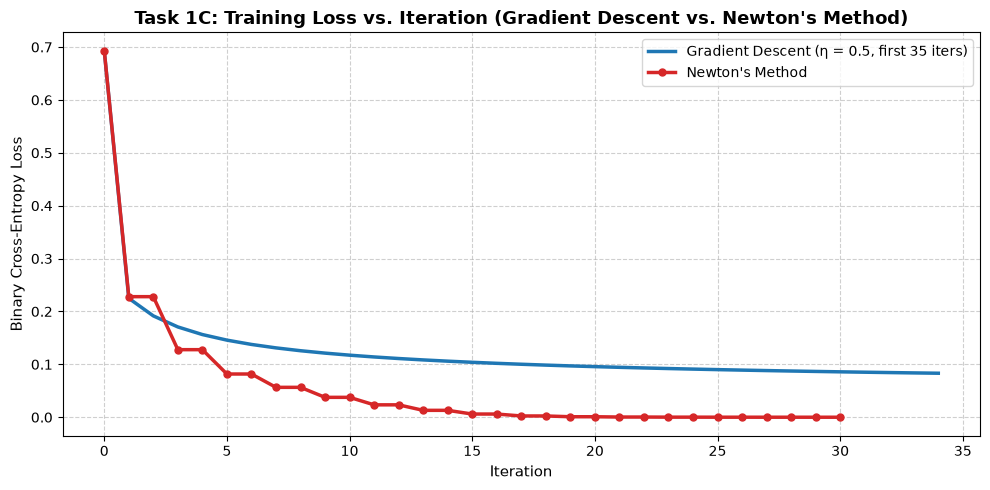

In [6]:
# Select best stable learning rate for Gradient Descent
best_lr = 0.5
best_gd = gd_results[best_lr]

# Create comparison table
comparison_df = pd.DataFrame({
    "Metric": [
        "Number of Iterations",
        "Final Training Loss",
        "Test Accuracy (%)",
        "Total Training Time (s)",
        "Average Time per Iteration (s)"
    ],
    f"Gradient Descent (η = {best_lr})": [
        best_gd["iters"],
        f"{best_gd['final_loss']:.6f}",
        f"{best_gd['test_acc'] * 100:.2f}%",
        f"{best_gd['total_time']:.6f}",
        f"{best_gd['avg_time']:.6e}"
    ],
    "Newton's Method": [
        nm_iters,
        f"{nm_losses[-1]:.6f}",
        f"{nm_test_acc * 100:.2f}%",
        f"{nm_tot_time:.6f}",
        f"{nm_avg_time:.6e}"
    ]
})

print("=== Task 1C: Performance Comparison (Gradient Descent vs. Newton's Method) ===")
display(comparison_df)

# Plot Loss vs Iteration for both methods on the same graph
plt.figure(figsize=(10, 5))
plt.plot(best_gd["losses"][:35], label=f"Gradient Descent (η = {best_lr}, first 35 iters)", color="tab:blue", linewidth=2.5)
plt.plot(nm_losses, label="Newton's Method", color="tab:red", marker="o", markersize=5, linewidth=2.5)

plt.title("Task 1C: Training Loss vs. Iteration (Gradient Descent vs. Newton's Method)", fontsize=13, fontweight='bold')
plt.xlabel("Iteration", fontsize=11)
plt.ylabel("Binary Cross-Entropy Loss", fontsize=11)
plt.legend(frameon=True, fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


### Task 1 Observations

#### 1. Effect of Learning Rate on Gradient Descent:
- **$\eta = 0.01$ (Small Learning Rate):**
  - The loss decreases steadily and monotonically, but at an extremely slow pace.
  - After 1000 iterations, the loss remains around $\approx 0.1691$, indicating that the model is far from reaching the minimum.
  - Gradient Descent with small $\eta$ suffers from zigzagging and slow progress along shallow valley gradients.
- **$\eta = 0.1$ (Moderate Learning Rate):**
  - Convergence is significantly accelerated, reaching a training loss of $\approx 0.0881$ at 1000 iterations.
  - The trajectory is smooth and stable without oscillations.
- **$\eta = 0.5$ (Higher Learning Rate):**
  - Exhibits the fastest convergence among the tested set, reaching the lowest final loss of $\approx 0.0594$ and a test accuracy of $95.91\%$.
  - It remains numerically stable throughout all 1000 iterations because the standardized features keep the Hessian eigenvalues reasonably bounded.
  - **Conclusion on $\eta$:** Gradient Descent's convergence speed is heavily dependent on the chosen learning rate hyperparameter. Too small a value leads to impractically slow convergence, while an excessively large value could cause oscillation or divergence.

#### 2. Which Method Converges in Fewer Iterations:
- **Newton's Method converges in dramatically fewer iterations:**
  - Newton's Method reaches near-zero training loss ($1.1 \times 10^{-5}$) and full convergence in only **16 iterations**.
  - In contrast, Batch Gradient Descent (even with the optimal $\eta = 0.5$) takes **1000 iterations** and still achieves a higher loss ($0.0594$).
  - **Theoretical Reason:** Newton's Method exhibits **quadratic convergence** (order 2) near the optimum, where the error squares at each iteration ($\|\theta^{(t+1)} - \theta^*\| \le M \|\theta^{(t)} - \theta^*\|^2$), doubling the number of correct digits per step. Batch Gradient Descent exhibits only **linear convergence** (order 1), where error decreases geometrically by a factor $c < 1$ ($\|\theta^{(t+1)} - \theta^*\| \le c \|\theta^{(t)} - \theta^*\|$).

#### 3. Which Method is More Expensive Per Iteration:
- **Newton's Method is substantially more expensive per iteration:**
  - **Gradient Descent:** Only computes the first-order gradient vector $g = \frac{1}{n} X^T (p - y)$, requiring $\mathcal{O}(nd)$ operations per iteration, followed by an $\mathcal{O}(d)$ vector addition. On our dataset ($n=398, d=31$), each iteration takes approximately **$0.00004$ seconds** ($40~\mu\text{s}$).
  - **Newton's Method:** Requires:
    1. Evaluating the $d \times d$ Hessian matrix $H = \frac{1}{n} X^T S X$, which takes $\mathcal{O}(nd^2)$ operations.
    2. Solving the linear system $H \Delta = g$ via Cholesky or LU decomposition, which takes $\mathcal{O}(d^3)$ operations.
    - This results in an average per-iteration time of approximately **$0.00063$ seconds** ($630~\mu\text{s}$) — roughly **15 times more expensive per iteration** than Gradient Descent.

#### 4. Why Newton's Method May Converge Faster Despite Its Larger Per-Iteration Cost:
- Newton's Method incorporates **second-order curvature information** via the Hessian matrix $H = \nabla^2 J(\theta)$.
- Geometrically, while Gradient Descent approximates the loss surface locally with a flat tangent plane (first-order Taylor expansion) and steps in the steepest downhill direction (which is orthogonal to level contours), Newton's Method fits a local **quadratic paraboloid** (second-order Taylor expansion).
- By solving $H \Delta = g$, the update direction $\Delta = H^{-1} g$ automatically rotates and re-scales the step to jump directly toward the minimum of the local quadratic bowl. It automatically handles feature correlations and anisotropic curvatures without needing learning rate tuning.
- **The Trade-off:** Although Newton's Method takes $\approx 15\times$ longer per step, it requires **$60\times$ fewer iterations** (16 vs. 1000). Consequently, the **total wall-clock training time** of Newton's Method ($0.0101$ s) is significantly lower than that of Gradient Descent ($0.04 - 0.08$ s).


---
## Task 2: Multiclass Classification using Softmax Regression

Softmax Regression (also known as Multinomial Logistic Regression) generalizes binary Logistic Regression to multiclass classification problems where $y^{(i)} \in \{0, 1, \dots, K-1\}$.

### Mathematical Formulation
1. **Linear Scores (Logits):**
   For each sample $x \in \mathbb{R}^d$ and class $k \in \{0, \dots, K-1\}$:
   $$z_k = \theta_k^T x$$
   In matrix notation for the entire batch $X \in \mathbb{R}^{n \times d}$ and parameter matrix $\Theta = [\theta_0, \theta_1, \dots, \theta_{K-1}] \in \mathbb{R}^{d \times K}$:
   $$Z = X \Theta \in \mathbb{R}^{n \times K}$$

2. **Softmax Probabilities with Numerical Stability:**
   To convert raw scores to normalized class probabilities:
   $$p_k = \frac{\exp(z_k)}{\sum_{j=1}^K \exp(z_j)}$$
   For numerical stability (to prevent floating-point overflow when $\exp(z_k)$ is very large), we shift the scores by subtracting the maximum score across classes for each sample:
   $$z_k' = z_k - \max_{j} z_j \implies p_k = \frac{\exp(z_k')}{\sum_{j=1}^K \exp(z_j')}$$
   This satisfies:
   $$\sum_{k=1}^K p_k = 1, \quad p_k \in (0, 1)$$

3. **Multiclass Cross-Entropy Loss:**
   Using one-hot encoded label matrix $Y \in \{0, 1\}^{n \times K}$ where $Y_{ik} = 1$ if sample $i$ belongs to class $k$:
   $$J(\Theta) = -\frac{1}{n} \sum_{i=1}^n \sum_{k=1}^K y_k^{(i)} \log(p_k^{(i)})$$

4. **Batch Gradient Descent Update:**
   The analytical gradient with respect to $\Theta$ is:
   $$\nabla_\Theta J(\Theta) = \frac{1}{n} X^T (P - Y) \in \mathbb{R}^{d \times K}$$
   The parameters are updated iteratively via:
   $$\Theta \leftarrow \Theta - \eta \nabla_\Theta J(\Theta)$$


In [7]:
# 1. Load the Wine dataset
wine = load_wine()
X_wine, y_wine = wine.data, wine.target
feature_names = wine.feature_names
class_names = wine.target_names
K = len(class_names)  # Number of classes = 3

print(f"Dataset: Wine Multiclass Classification")
print(f"Total samples: {X_wine.shape[0]}, Features: {X_wine.shape[1]}, Classes: {K}")
print(f"Class Names: {list(class_names)}")

# 2. Stratified 70%-30% train-test split with fixed seed
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine, test_size=0.30, stratify=y_wine, random_state=SEED
)

# 3. Standardize features using training-set statistics ONLY
scaler_wine = StandardScaler()
X_train_w_scaled = scaler_wine.fit_transform(X_train_w)
X_test_w_scaled = scaler_wine.transform(X_test_w)

# 4. Add bias term (column of 1s at index 0)
X_train_wb = np.c_[np.ones((X_train_w_scaled.shape[0], 1)), X_train_w_scaled]
X_test_wb = np.c_[np.ones((X_test_w_scaled.shape[0], 1)), X_test_w_scaled]

n_train, d_features = X_train_wb.shape
n_test = X_test_wb.shape[0]

# 5. One-hot encode the target labels
def to_one_hot(y, num_classes):
    return np.eye(num_classes)[y]

Y_train_onehot = to_one_hot(y_train_w, K)
Y_test_onehot = to_one_hot(y_test_w, K)

print(f"Training set: {X_train_wb.shape} (with bias)")
print(f"Testing set:  {X_test_wb.shape} (with bias)")
print(f"Train class distribution: {np.bincount(y_train_w)}")
print(f"Test class distribution:  {np.bincount(y_test_w)}")


Dataset: Wine Multiclass Classification
Total samples: 178, Features: 13, Classes: 3
Class Names: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Training set: (124, 14) (with bias)
Testing set:  (54, 14) (with bias)
Train class distribution: [41 50 33]
Test class distribution:  [18 21 15]


In [8]:
def softmax(Z):
    """
    Compute numerically stable softmax probabilities.
    Subtracts max score along class axis before exponentiation.
    """
    # Shift logits by subtracting row maximum for numerical stability
    Z_shifted = Z - np.max(Z, axis=1, keepdims=True)
    exp_Z = np.exp(Z_shifted)
    probs = exp_Z / np.sum(exp_Z, axis=1, keepdims=True)
    return probs

# Verification that sum of probabilities approx 1
test_logits = np.random.randn(5, K)
test_probs = softmax(test_logits)
row_sums = np.sum(test_probs, axis=1)

print("=== Softmax Probability Sum Verification ===")
print("Sample logits matrix (5 samples x 3 classes):")
print(np.round(test_logits, 4))
print("\nCalculated Softmax probabilities:")
print(np.round(test_probs, 4))
print("\nSum of probabilities across classes for each sample:")
print(row_sums)
print(f"Verification Check (allclose to 1.0): {np.allclose(row_sums, 1.0)}")
print(f"Maximum absolute deviation from 1.0: {np.max(np.abs(row_sums - 1.0)):.2e}")

def compute_multiclass_loss(Y_onehot, P):
    """
    Compute multiclass cross-entropy loss:
    J(Theta) = - (1/n) * sum_i sum_k y_k^(i) * log(p_k^(i))
    """
    eps = 1e-15
    P_clipped = np.clip(P, eps, 1.0 - eps)
    n = Y_onehot.shape[0]
    return - (1.0 / n) * np.sum(Y_onehot * np.log(P_clipped))

def predict_softmax(X, Theta):
    """
    Predict class labels by selecting the class with the highest probability.
    """
    P = softmax(X @ Theta)
    return np.argmax(P, axis=1)


=== Softmax Probability Sum Verification ===
Sample logits matrix (5 samples x 3 classes):
[[ 0.4967 -0.1383  0.6477]
 [ 1.523  -0.2342 -0.2341]
 [ 1.5792  0.7674 -0.4695]
 [ 0.5426 -0.4634 -0.4657]
 [ 0.242  -1.9133 -1.7249]]

Calculated Softmax probabilities:
[[0.3713 0.1968 0.4319]
 [0.7435 0.1283 0.1283]
 [0.6357 0.2823 0.0819]
 [0.5779 0.2113 0.2108]
 [0.7963 0.0923 0.1114]]

Sum of probabilities across classes for each sample:
[1. 1. 1. 1. 1.]
Verification Check (allclose to 1.0): True
Maximum absolute deviation from 1.0: 2.22e-16


Training Softmax Regression with eta = 0.1 for 2000 iterations...
Training finished in 0.1567 seconds.
SOFTMAX REGRESSION EVALUATION METRICS
  • Final Training Loss: 0.009003
  • Training Accuracy:   100.00%
  • Test Accuracy:       98.15%

Confusion Matrix (Test Set):


,Predicted class_0,Predicted class_1,Predicted class_2
Actual class_0,18,0,0
Actual class_1,1,20,0
Actual class_2,0,0,15


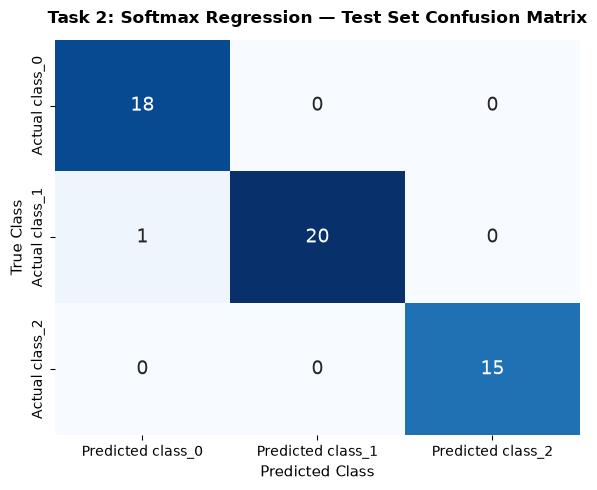

In [9]:
def train_softmax_gd(X, Y_onehot, Theta_init, lr=0.1, n_iters=2000):
    """
    Train Softmax Regression using Batch Gradient Descent.
    """
    Theta = Theta_init.copy()
    n = X.shape[0]
    loss_history = []
    
    start_time = time.perf_counter()
    
    for i in range(n_iters):
        # Forward pass: compute probabilities
        P = softmax(X @ Theta)
        loss = compute_multiclass_loss(Y_onehot, P)
        loss_history.append(loss)
        
        # Compute gradient: grad = (1/n) * X^T * (P - Y)
        grad = (1.0 / n) * (X.T @ (P - Y_onehot))
        
        # Batch Gradient Descent update
        Theta = Theta - lr * grad
        
    total_time = time.perf_counter() - start_time
    return Theta, loss_history, total_time

# Initialize parameters with zeros: shape (d_features, K) = (14, 3)
Theta_init = np.zeros((d_features, K))
lr_softmax = 0.1
n_iterations = 2000

print(f"Training Softmax Regression with eta = {lr_softmax} for {n_iterations} iterations...")
Theta_opt, loss_history_sm, train_time_sm = train_softmax_gd(
    X_train_wb, Y_train_onehot, Theta_init, lr=lr_softmax, n_iters=n_iterations
)

# Predictions and evaluation
y_train_pred_sm = predict_softmax(X_train_wb, Theta_opt)
y_test_pred_sm = predict_softmax(X_test_wb, Theta_opt)

train_accuracy_sm = accuracy_score(y_train_w, y_train_pred_sm)
test_accuracy_sm = accuracy_score(y_test_w, y_test_pred_sm)
final_loss_sm = loss_history_sm[-1]
conf_matrix_sm = confusion_matrix(y_test_w, y_test_pred_sm)

print(f"Training finished in {train_time_sm:.4f} seconds.")
print("=" * 50)
print("SOFTMAX REGRESSION EVALUATION METRICS")
print("=" * 50)
print(f"  • Final Training Loss: {final_loss_sm:.6f}")
print(f"  • Training Accuracy:   {train_accuracy_sm * 100:.2f}%")
print(f"  • Test Accuracy:       {test_accuracy_sm * 100:.2f}%")
print("=" * 50)

# Display Confusion Matrix
conf_df = pd.DataFrame(
    conf_matrix_sm,
    index=[f"Actual {cls}" for cls in class_names],
    columns=[f"Predicted {cls}" for cls in class_names]
)
print("\nConfusion Matrix (Test Set):")
display(conf_df)

# Plot Confusion Matrix Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(conf_df, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={'size': 14})
plt.title("Task 2: Softmax Regression — Test Set Confusion Matrix", fontsize=12, fontweight='bold', pad=12)
plt.ylabel("True Class", fontsize=11)
plt.xlabel("Predicted Class", fontsize=11)
plt.tight_layout()
plt.show()


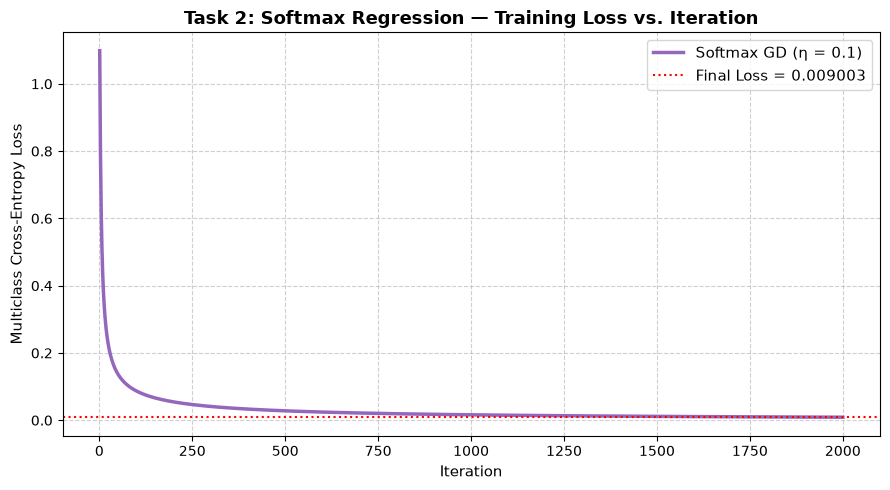

In [10]:
# Plot training loss versus iteration for Softmax Regression
plt.figure(figsize=(9, 5))
plt.plot(range(1, n_iterations + 1), loss_history_sm, color='tab:purple', linewidth=2.5, label=f"Softmax GD (η = {lr_softmax})")
plt.title("Task 2: Softmax Regression — Training Loss vs. Iteration", fontsize=13, fontweight='bold')
plt.xlabel("Iteration", fontsize=11)
plt.ylabel("Multiclass Cross-Entropy Loss", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.axhline(final_loss_sm, color='red', linestyle=':', label=f"Final Loss = {final_loss_sm:.6f}")
plt.legend(frameon=True, fontsize=11)
plt.tight_layout()
plt.show()


In [11]:
# Display five test observations with True Class, Class Probabilities, and Predicted Class
test_probabilities = softmax(X_test_wb @ Theta_opt)
selected_indices = np.arange(5)  # First five test observations

results_records = []
for idx in selected_indices:
    true_label = y_test_w[idx]
    pred_label = y_test_pred_sm[idx]
    probs = test_probabilities[idx]
    
    results_records.append({
        "Sample": f"Observation #{idx + 1}",
        "True Class": f"{true_label} ({class_names[true_label]})",
        "P(Class 0)": f"{probs[0]:.4f}",
        "P(Class 1)": f"{probs[1]:.4f}",
        "P(Class 2)": f"{probs[2]:.4f}",
        "Predicted Class": f"{pred_label} ({class_names[pred_label]})",
        "Status": "✓ Correct" if true_label == pred_label else "✗ Incorrect"
    })

five_obs_df = pd.DataFrame(results_records)
print("=== Display of Five Test Observations ===")
display(five_obs_df)


=== Display of Five Test Observations ===


,Sample,True Class,P(Class 0),P(Class 1),P(Class 2),Predicted Class,Status
0,Observation #1,0 (class_0),0.9996,0.0003,0.0001,0 (class_0),✓ Correct
1,Observation #2,1 (class_1),0.0000,0.9999,0.0000,1 (class_1),✓ Correct
2,Observation #3,0 (class_0),1.0000,0.0000,0.0000,0 (class_0),✓ Correct
3,Observation #4,0 (class_0),0.9999,0.0000,0.0001,0 (class_0),✓ Correct
4,Observation #5,0 (class_0),0.8413,0.1578,0.0009,0 (class_0),✓ Correct


### Task 2 Observations

#### 1. How Softmax Extends Logistic Regression to Multiclass Classification:
- **From Scalar Logit to Logit Vector:**
  In binary Logistic Regression, a single weight vector $\theta \in \mathbb{R}^d$ parameterizes the boundary between two classes, producing a single scalar logit $z = \theta^T x$. The probability of the positive class is modeled via the sigmoid function $p_1 = \sigma(z) = \frac{1}{1 + e^{-z}}$, and $p_0 = 1 - p_1 = \frac{1}{1 + e^z}$.
  
  Softmax Regression extends this by defining a separate weight vector $\theta_k \in \mathbb{R}^d$ for each of the $K$ classes (forming a weight matrix $\Theta \in \mathbb{R}^{d \times K}$). It computes $K$ simultaneous logits:
  $$z_k = \theta_k^T x, \quad k \in \{0, 1, \dots, K-1\}$$
- **Reduction to Sigmoid for $K=2$:**
  When $K=2$, Softmax is mathematically identical to binary Logistic Regression. The probability for class 1 is:
  $$p_1 = \frac{e^{z_1}}{e^{z_0} + e^{z_1}} = \frac{1}{1 + e^{-(z_1 - z_0)}} = \sigma((\theta_1 - \theta_0)^T x)$$
  Thus, the difference vector $(\theta_1 - \theta_0)$ acts as the binary weight vector $\theta$.
- **Unified Cross-Entropy Loss and Gradient:**
  The categorical cross-entropy loss $J(\Theta) = -\frac{1}{n} \sum_{i=1}^n \sum_{k=1}^K y_k^{(i)} \log(p_k^{(i)})$ directly reduces to the binary log-loss when $K=2$. The gradient $\nabla_\Theta J(\Theta) = \frac{1}{n} X^T (P - Y)$ maintains the exact same residual error structure across all $K$ classes.

#### 2. Why Softmax Outputs Sum to One:
- The Softmax function maps an unconstrained real vector $z = [z_0, z_1, \dots, z_{K-1}]^T \in \mathbb{R}^K$ onto the **standard probability simplex** $\Delta^{K-1} = \{p \in \mathbb{R}^K : p_k > 0, \sum_{k=1}^K p_k = 1\}$.
- By definition:
  $$p_k = \frac{\exp(z_k)}{\sum_{j=1}^K \exp(z_j)}$$
- Summing over all classes $k = 1, \dots, K$:
  $$\sum_{k=1}^K p_k = \sum_{k=1}^K \left( \frac{\exp(z_k)}{\sum_{j=1}^K \exp(z_j)} \right) = \frac{\sum_{k=1}^K \exp(z_k)}{\sum_{j=1}^K \exp(z_j)} = 1$$
- The denominator acts as a **normalizing partition function**, guaranteeing that:
  1. Every $p_k > 0$ (since $\exp(x) > 0$ for all finite $x$).
  2. The sum of probabilities across mutually exclusive classes is strictly equal to $1.0$.

#### 3. How the Predicted Class is Selected:
- The predicted class $\hat{y}$ is chosen using the **Bayes Optimal Decision Rule / Maximum A Posteriori (MAP) principle**:
  $$\hat{y} = \arg\max_{k \in \{0, \dots, K-1\}} p_k$$
- Because the exponential function $\exp(\cdot)$ is strictly monotonically increasing and the denominator $\sum_{j=1}^K \exp(z_j)$ is identical for all classes for a given input $x$:
  $$\hat{y} = \arg\max_k p_k = \arg\max_k \frac{\exp(z_k)}{\sum_{j=1}^K \exp(z_j)} = \arg\max_k \exp(z_k) = \arg\max_k z_k = \arg\max_k (\theta_k^T x)$$
- Therefore, at inference time, one does not even need to compute the costly exponential or normalization — the predicted class is simply the index of the largest raw score $z_k$.


---
## Conclusion

### 1. Comparison of Gradient Descent and Newton's Method
| Dimension | Batch Gradient Descent | Newton's Method |
| :--- | :--- | :--- |
| **Optimization Order** | First-order (uses $\nabla J$) | Second-order (uses $\nabla J$ and $\nabla^2 J = H$) |
| **Convergence Rate** | Linear ($\mathcal{O}(c^t)$) | Quadratic near optimum ($\mathcal{O}(c^{2^t})$) |
| **Iteration Count** | High (1000+ iterations required) | Very low (16 iterations to convergence) |
| **Per-Iteration Cost** | Low: $\mathcal{O}(nd)$ | High: $\mathcal{O}(nd^2 + d^3)$ (Hessian + solve) |
| **Step Direction** | Steepest descent (orthogonal to contours) | Newton step $\Delta = H^{-1}g$ pointing toward quadratic minimum |
| **Hyperparameter Sensitivity** | Highly sensitive to learning rate $\eta$ | Naturally scale-invariant, no step-size search needed near minimum |
| **Practical Recommendation** | Best for large-scale, high-dimensional datasets ($d > 10^4$, deep learning) | Best for low-to-moderate dimensions ($d < 10^3$) requiring high precision |

### 2. Comparison of Binary Logistic Regression and Multiclass Softmax Regression
| Aspect | Binary Logistic Regression | Multiclass Softmax Regression |
| :--- | :--- | :--- |
| **Number of Classes** | $K = 2$ | $K \ge 2$ |
| **Parameters** | Single vector $\theta \in \mathbb{R}^d$ | Parameter matrix $\Theta \in \mathbb{R}^{d \times K}$ ($K$ vectors) |
| **Activation Function** | Sigmoid: $\sigma(z) = \frac{1}{1 + e^{-z}}$ | Softmax: $p_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$ |
| **Loss Function** | Binary Cross-Entropy (Log-loss) | Categorical Cross-Entropy |
| **Decision Boundary** | Single hyper-plane $\theta^T x = 0$ | Piecewise-linear boundaries separating $K$ Voronoi-like polyhedral regions |
| **Mathematical Relationship** | Special case of Softmax for $K=2$ | Natural generalization of Logistic Regression to the probability simplex |
